# Toxoplasma gondii: adding biological and exposure risk factors from NHANES

**Question:** the current model (`toxo_model_overview.ipynb`) reaches a cross-validated ROC-AUC of about **0.72**
using demographics, education, income, Toxocara and a few behaviour items. Most of its signal comes from
socio-economic proxies. Can NHANES variables that sit closer to *how people actually get infected*
(other infections with the same transmission routes, blood and environmental markers, food, water, housing, work)
push the score higher?

**Data rule:** NHANES only. Everything here comes from official CDC NHANES XPT files and is joined on `SEQN`.

**What this notebook does**
1. **The new risk factors**: 44 columns from 20 NHANES 2013-2014 files, and why each one is linked to Toxoplasma
2. **The data**: missing values, positivity rate for every factor (like Table I), crude and age-adjusted odds ratios
3. **Models**: the same protocol as `scripts/train_baseline.py` (same 80/20 split, same 15 CV folds, same 4 models), old vs new feature sets
4. **Test set**: ROC-AUC with 95% CI, accuracy, balanced accuracy, sensitivity, specificity, F1
5. **Which features the model uses**: permutation importance
6. **More rows instead of more columns**: NHANES 2009-2010 and 2011-2012 used the *same* Toxoplasma assay and cutoff, so the cohort can be tripled to 14,649 adults
7. **Summary**

Note on "accuracy": the 0.72 in the earlier notebook is **ROC-AUC**, not accuracy. Plain accuracy is about 85% for every
model, but an always-negative guess also scores 85% (only 15% are positive). ROC-AUC stays the main metric here.

In [1]:
import os
import sys
import warnings

# The notebook lives in research_r/; all project paths are relative to the repo root
if os.path.basename(os.getcwd()) == 'research_r':
    os.chdir('..')
print('Working directory:', os.getcwd())
sys.path.insert(0, 'scripts')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from joblib import Parallel, delayed
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix)
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

import build_bio_features as bbf

warnings.filterwarnings('ignore')
os.environ['PYTHONWARNINGS'] = 'ignore'   # also silence warnings inside the parallel worker processes
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)
pd.set_option('display.max_rows', 200)

# Same chart style as toxo_model_overview.ipynb
INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
SET_COLORS = {'B_demo_toxocara': '#2a78d6', 'C_all': '#eb6834', 'D_C+questionnaire': '#1baf7a',
              'E_C+lab': '#eda100', 'F_everything': '#e87ba4'}
SINGLE, REFERENCE = '#2a78d6', '#8a8985'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'text.color': INK,
    'font.size': 10, 'legend.frameon': False, 'figure.dpi': 110,
})

RANDOM_STATE = 42
TARGET = 'target_toxo_pos'
REBUILD = False   # True = rebuild both CSVs from the raw XPT files (downloads missing files from CDC)

if REBUILD or not (os.path.exists(bbf.OUT_CSV) and os.path.exists(bbf.OUT_POOLED_CSV)):
    bbf.main()
df = pd.read_csv(bbf.OUT_CSV)
pooled = pd.read_csv(bbf.OUT_POOLED_CSV)
print(f'2013-2014 cohort: {df.shape[0]:,} adults, {df.shape[1]} columns ({df[TARGET].mean():.1%} positive)')
print(f'2009-2014 pooled: {pooled.shape[0]:,} adults')

Working directory: /home/claude/toxo


2013-2014 cohort: 5,006 adults, 63 columns (15.0% positive)
2009-2014 pooled: 14,649 adults


---
## 1. The new risk factors

Toxoplasma is caught in three main ways: **eating undercooked meat** with tissue cysts, **swallowing oocysts** from cat faeces
(soil, unwashed produce, untreated water), and **mother-to-child**. NHANES 2013-2014 has no question about cats or meat doneness,
so the factors below measure those routes **indirectly**:

- **Other infections with the same route** (lab): hepatitis A and Toxocara are faecal-oral / soil-borne; hepatitis E is food-borne (pork, game);
  HSV-1 is a marker of crowded childhood living conditions; HIV, hepatitis B and C mark immune suppression and blood/needle exposure.
- **Blood markers** (lab): eosinophils rise with parasite infections; blood lead tracks soil/dust contact and older housing; mercury tracks fish and seafood.
- **Food and water** (questionnaire): well/spring water, shellfish and oysters in the last 30 days, grams of beef, pork, lamb/game, poultry, organ meat/sausage and fish eaten yesterday.
- **Living conditions and work** (questionnaire/exam): crowding, renting, Spanish-language interview, citizenship, military service abroad,
  farm / food-service / construction work, food insecurity, no health insurance, drug injection, hepatitis A vaccine, missing teeth.

`SSTOXM` (Toxoplasma IgM) and `SSTOXAV` (avidity) are **not** used: they are measurements of Toxoplasma itself and would leak the label.

In [2]:
catalog = [
    # feature, group, NHANES file, NHANES variable(s), link to Toxoplasma, who was tested
    ('hav_antibody', 'Lab: infection', 'HEPA_H', 'LBXHA', 'Hepatitis A antibodies: faecal-oral exposure (or vaccine)', 'all ages'),
    ('hav_natural_infection', 'Lab: infection', 'HEPA_H + IMQ_H', 'LBXHA, IMQ011', 'HAV antibody AND never vaccinated = past natural faecal-oral infection', 'all ages'),
    ('hev_igg', 'Lab: infection', 'HEPE_H', 'LBDHEG', 'Hepatitis E IgG: food-borne zoonosis (pork, game, water)', 'age 6+'),
    ('hbv_core_antibody', 'Lab: infection', 'HEPBD_H', 'LBXHBC', 'Past hepatitis B infection: blood/sexual exposure', 'age 6+'),
    ('hcv_antibody', 'Lab: infection', 'HEPC_H', 'LBXHCR', 'Hepatitis C antibody: needle/blood exposure', 'age 6+'),
    ('hsv1', 'Lab: infection', 'HSV_H', 'LBXHE1', 'Herpes simplex 1: marker of crowded childhood conditions', 'ages 14-49 only'),
    ('hsv2', 'Lab: infection', 'HSV_H', 'LBXHE2', 'Herpes simplex 2: sexual exposure', 'ages 14-49 only'),
    ('hiv', 'Lab: infection', 'HIV_H', 'LBDHI', 'HIV: immune suppression (the paper\'s target group)', 'ages 18-59 only'),
    ('toxocara_mfi_log', 'Lab: infection', 'SSTOCA_H', 'SSTCAMFI', 'Toxocara antibody LEVEL (continuous; dog/cat faeces in soil)', 'age 6+'),
    ('wbc_count', 'Lab: blood', 'CBC_H', 'LBXWBCSI', 'White blood cells: immune activity', 'all'),
    ('eosinophil_pct', 'Lab: blood', 'CBC_H', 'LBXEOPCT', 'Eosinophils: rise with parasite infections', 'all'),
    ('lymphocyte_pct', 'Lab: blood', 'CBC_H', 'LBXLYPCT', 'Lymphocytes: immune status', 'all'),
    ('monocyte_pct', 'Lab: blood', 'CBC_H', 'LBXMOPCT', 'Monocytes: Toxoplasma travels inside monocytes', 'all'),
    ('hemoglobin', 'Lab: blood', 'CBC_H', 'LBXHGB', 'Anaemia / nutrition', 'all'),
    ('blood_lead_log', 'Lab: environment', 'PBCD_H', 'LBXBPB', 'Lead: soil and dust contact, older housing', 'half sample'),
    ('blood_cadmium_log', 'Lab: environment', 'PBCD_H', 'LBXBCD', 'Cadmium: smoking, diet, environment', 'half sample'),
    ('blood_mercury_log', 'Lab: environment', 'PBCD_H', 'LBXTHG', 'Mercury: fish and seafood intake', 'half sample'),
    ('cotinine_log', 'Lab: environment', 'COT_H', 'LBXCOT', 'Cotinine: measured tobacco smoke exposure', 'all'),
    ('well_or_spring_water', 'Questionnaire: food & water', 'DR1TOT_H', 'DR1TWS', 'Tap water from a well, cistern or spring (untreated water)', 'all'),
    ('no_tap_water', 'Questionnaire: food & water', 'DR1TOT_H', 'DR1TWS', 'Does not drink tap water', 'all'),
    ('shellfish_30d', 'Questionnaire: food & water', 'DR1TOT_H', 'DRD340', 'Shellfish eaten in last 30 days', 'all'),
    ('oysters_30d', 'Questionnaire: food & water', 'DR1TOT_H', 'DRD350F', 'Oysters in last 30 days (raw oysters are a US risk factor)', 'all'),
    ('fish_30d', 'Questionnaire: food & water', 'DR1TOT_H', 'DRD360', 'Fish eaten in last 30 days', 'all'),
    ('beef_g_log', 'Questionnaire: food & water', 'DR1IFF_H', 'DR1IFDCD 21xxxxxx', 'Grams of beef eaten yesterday (24-h recall)', 'all'),
    ('pork_g_log', 'Questionnaire: food & water', 'DR1IFF_H', 'DR1IFDCD 22xxxxxx', 'Grams of pork yesterday (pork carries tissue cysts)', 'all'),
    ('lamb_veal_game_g_log', 'Questionnaire: food & water', 'DR1IFF_H', 'DR1IFDCD 23xxxxxx', 'Grams of lamb, veal, goat, venison, game yesterday', 'all'),
    ('poultry_g_log', 'Questionnaire: food & water', 'DR1IFF_H', 'DR1IFDCD 24xxxxxx', 'Grams of poultry yesterday (paper: grilled/smoked poultry)', 'all'),
    ('organ_sausage_lunchmeat_g_log', 'Questionnaire: food & water', 'DR1IFF_H', 'DR1IFDCD 25xxxxxx', 'Grams of organ meat, sausage, cured meat yesterday', 'all'),
    ('fish_shellfish_g_log', 'Questionnaire: food & water', 'DR1IFF_H', 'DR1IFDCD 26xxxxxx', 'Grams of fish and shellfish yesterday', 'all'),
    ('household_size', 'Questionnaire: living & work', 'DEMO_H', 'DMDHHSIZ', 'People in household', 'all'),
    ('crowding', 'Questionnaire: living & work', 'DEMO_H + HOQ_H', 'DMDHHSIZ / HOD050', 'People per room', 'all'),
    ('home_rented', 'Questionnaire: living & work', 'HOQ_H', 'HOQ065', 'Home rented / other arrangement', 'all'),
    ('spanish_interview', 'Questionnaire: living & work', 'DEMO_H', 'SIALANG', 'Interview done in Spanish (recent migration)', 'all'),
    ('not_us_citizen', 'Questionnaire: living & work', 'DEMO_H', 'DMDCITZN', 'Not a US citizen', 'all'),
    ('military_abroad', 'Questionnaire: living & work', 'DEMO_H', 'DMQMILIZ, DMQADFC', 'Served in the military in a foreign country', 'all'),
    ('work_agriculture', 'Questionnaire: living & work', 'OCQ_H', 'OCD231/241/391/392', 'Farming, fishing, forestry work (soil, animals)', 'all'),
    ('work_food_service', 'Questionnaire: living & work', 'OCQ_H', 'OCD231/241/391/392', 'Food preparation / serving work (raw meat handling)', 'all'),
    ('work_construction_soil', 'Questionnaire: living & work', 'OCQ_H', 'OCD231/241/391/392', 'Construction, grounds-keeping (soil contact)', 'all'),
    ('food_insecurity', 'Questionnaire: living & work', 'FSQ_H', 'FSDAD', 'Adult food security, 0 = full ... 3 = very low', 'all'),
    ('no_health_insurance', 'Questionnaire: living & work', 'HIQ_H', 'HIQ011', 'No health insurance', 'all'),
    ('inject_drugs_ever', 'Questionnaire: living & work', 'DUQ_H', 'DUQ370', 'Ever injected drugs (risk factor in the paper)', 'ages 18-69 only'),
    ('hard_drugs_ever', 'Questionnaire: living & work', 'DUQ_H', 'DUQ240', 'Ever used cocaine, heroin or methamphetamine', 'ages 18-69 only'),
    ('hav_vaccinated', 'Questionnaire: living & work', 'IMQ_H', 'IMQ011', 'Received hepatitis A vaccine (travel / health access)', 'all'),
    ('missing_teeth', 'Questionnaire: living & work', 'OHXDEN_H', 'OHX02TC-OHX31TC', 'Missing permanent teeth (exam; paper used tooth loss)', 'all'),
]
catalog = pd.DataFrame(catalog, columns=['feature', 'group', 'NHANES file', 'NHANES variable', 'link to Toxoplasma', 'tested in'])
assert set(catalog['feature']) == set(bbf.NEW_FEATURES), 'catalog and feature list differ'
catalog['non-missing (%)'] = catalog['feature'].map(lambda c: round(100 * df[c].notna().mean(), 1))
print(f"{len(catalog)} new features from {catalog['NHANES file'].str.split(' ').str[0].nunique()} NHANES files")
print(catalog.groupby('group').size().to_string())
display(catalog)

44 new features from 20 NHANES files
group
Lab: blood                       5
Lab: environment                 4
Lab: infection                   9
Questionnaire: food & water     11
Questionnaire: living & work    15


,feature,group,NHANES file,NHANES variable,link to Toxoplasma,tested in,non-missing (%)
0,hav_antibody,Lab: infection,HEPA_H,LBXHA,Hepatitis A antibodies: faecal-oral exposure (...,all ages,100.0
1,hav_natural_infection,Lab: infection,HEPA_H + IMQ_H,"LBXHA, IMQ011",HAV antibody AND never vaccinated = past natur...,all ages,100.0
2,hev_igg,Lab: infection,HEPE_H,LBDHEG,"Hepatitis E IgG: food-borne zoonosis (pork, ga...",age 6+,100.0
3,hbv_core_antibody,Lab: infection,HEPBD_H,LBXHBC,Past hepatitis B infection: blood/sexual exposure,age 6+,100.0
4,hcv_antibody,Lab: infection,HEPC_H,LBXHCR,Hepatitis C antibody: needle/blood exposure,age 6+,99.9
5,hsv1,Lab: infection,HSV_H,LBXHE1,Herpes simplex 1: marker of crowded childhood ...,ages 14-49 only,52.9
6,hsv2,Lab: infection,HSV_H,LBXHE2,Herpes simplex 2: sexual exposure,ages 14-49 only,52.7
7,hiv,Lab: infection,HIV_H,LBDHI,HIV: immune suppression (the paper's target gr...,ages 18-59 only,68.6
8,toxocara_mfi_log,Lab: infection,SSTOCA_H,SSTCAMFI,Toxocara antibody LEVEL (continuous; dog/cat f...,age 6+,100.0
9,wbc_count,Lab: blood,CBC_H,LBXWBCSI,White blood cells: immune activity,all,99.9


---
## 2. The data
### 2.1 Positivity rate by risk factor (same layout as Table I)
For yes/no factors: the share of Toxoplasma-positive people in each group. For continuous factors: the share positive in each quartile.
Overall positivity is 15.0%.

In [3]:
def positivity_rows(col):
    x, y = df[col], df[TARGET]
    rows = []
    if x.nunique() <= 4:
        levels = sorted(x.dropna().unique())
        names = {0.0: 'no', 1.0: 'yes'} if set(levels) <= {0.0, 1.0} else {v: f'= {v:g}' for v in levels}
        for v in levels:
            m = x == v
            rows.append((col, names[v], int(m.sum()), 100 * y[m].mean()))
    else:
        q = pd.qcut(x, 4, duplicates='drop')
        for i, (iv, g) in enumerate(y.groupby(q, observed=True)):
            rows.append((col, f'Q{i + 1}: {iv.left:.2f} to {iv.right:.2f}', len(g), 100 * g.mean()))
    if x.isna().any():
        m = x.isna()
        rows.append((col, 'missing', int(m.sum()), 100 * y[m].mean()))
    return rows

table1 = pd.DataFrame([r for c in bbf.NEW_FEATURES for r in positivity_rows(c)],
                      columns=['feature', 'group', 'n', 'positive (%)'])
table1['positive (%)'] = table1['positive (%)'].round(1)
display(table1)

,feature,group,n,positive (%)
0,hav_natural_infection,no,3488,12.6
1,hav_natural_infection,yes,1518,20.6
2,hav_antibody,no,2667,11.5
3,hav_antibody,yes,2339,19.0
4,hev_igg,no,4712,14.6
5,hev_igg,yes,294,20.4
6,hbv_core_antibody,no,4635,14.6
7,hbv_core_antibody,yes,371,19.7
8,hcv_antibody,no,4876,15.1
9,hcv_antibody,yes,127,12.6


### 2.2 How strong is each factor on its own, and after adjusting for age, sex and birthplace?
Many factors are linked to Toxoplasma only because they are linked to **age** (older people had more time to be exposed) or **being born abroad**.
The age-adjusted odds ratio separates this: a factor that stays above 1 after adjustment adds information the old model did not have.

- Continuous factors: odds ratio **per 1 standard deviation**. Yes/no factors: odds ratio **yes vs no**.
- Adjusted model: factor + age + sex + born abroad, logistic regression, complete cases for that factor, 95% Wald CI.
- `AUC alone`: ROC-AUC of the raw factor by itself (0.5 = no information).

In [4]:
def logit_fit(X, y, iters=50):
    # Plain logistic regression (Newton-Raphson) returning coefficients and standard errors
    X = np.column_stack([np.ones(len(X)), X])
    beta = np.zeros(X.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-X @ beta))
        W = p * (1 - p)
        H = X.T @ (X * W[:, None]) + 1e-8 * np.eye(X.shape[1])
        step = np.linalg.solve(H, X.T @ (y - p))
        beta += step
        if np.abs(step).max() < 1e-8:
            break
    se = np.sqrt(np.diag(np.linalg.inv(H)))
    return beta[1:], se[1:]

adj = pd.DataFrame({'age_10y': df['RIDAGEYR'] / 10, 'male': (df['RIAGENDR'] == 1).astype(float),
                    'born_abroad': (df['DMDBORN4'] == 2).astype(float)})
or_rows = []
for col in bbf.NEW_FEATURES:
    x = df[col]
    binary = set(x.dropna().unique()) <= {0.0, 1.0}
    xs = x if binary else (x - x.mean()) / x.std()
    m = x.notna() & adj.notna().all(axis=1)
    yv = df.loc[m, TARGET].to_numpy(float)
    b0, s0 = logit_fit(xs[m].to_numpy()[:, None], yv)
    b1, s1 = logit_fit(np.column_stack([xs[m].to_numpy(), adj[m].to_numpy()]), yv)
    z = b1[0] / s1[0]
    or_rows.append({'feature': col, 'group': catalog.set_index('feature').loc[col, 'group'],
                    'scale': 'yes vs no' if binary else 'per 1 SD', 'n': int(m.sum()),
                    'AUC alone': roc_auc_score(yv, x[m]),
                    'crude OR': np.exp(b0[0]), 'adj OR': np.exp(b1[0]),
                    'adj OR 95% low': np.exp(b1[0] - 1.96 * s1[0]), 'adj OR 95% high': np.exp(b1[0] + 1.96 * s1[0]),
                    'adj p': 2 * stats.norm.sf(abs(z))})
or_table = pd.DataFrame(or_rows).sort_values('adj p').reset_index(drop=True)
display(or_table.round(3))
sig = or_table[or_table['adj p'] < 0.05]
print(f'{len(sig)} of {len(or_table)} factors stay significant (p < 0.05) after adjusting for age, sex and birthplace:')
print('  ' + ', '.join(f"{r.feature} (OR {r['adj OR']:.2f})" for _, r in sig.iterrows()))

,feature,group,scale,n,AUC alone,crude OR,adj OR,adj OR 95% low,adj OR 95% high,adj p
0,toxocara_mfi_log,Lab: infection,per 1 SD,5006,0.616,1.508,1.390,1.296,1.492,0.000
1,spanish_interview,Questionnaire: living & work,yes vs no,5006,0.581,3.792,2.832,2.200,3.646,0.000
2,no_health_insurance,Questionnaire: living & work,yes vs no,5002,0.537,1.510,1.881,1.543,2.295,0.000
3,crowding,Questionnaire: living & work,per 1 SD,4945,0.520,1.119,1.194,1.106,1.289,0.000
4,missing_teeth,Questionnaire: living & work,per 1 SD,4713,0.623,1.406,1.199,1.103,1.304,0.000
5,household_size,Questionnaire: living & work,per 1 SD,5006,0.503,1.046,1.198,1.099,1.306,0.000
6,food_insecurity,Questionnaire: living & work,per 1 SD,4955,0.520,1.068,1.169,1.079,1.265,0.000
7,not_us_citizen,Questionnaire: living & work,yes vs no,5000,0.554,2.239,1.608,1.242,2.081,0.000
8,hsv2,Lab: infection,yes vs no,2639,0.542,1.721,1.805,1.309,2.490,0.000
9,blood_mercury_log,Lab: environment,per 1 SD,2502,0.508,1.002,0.821,0.731,0.923,0.001


17 of 44 factors stay significant (p < 0.05) after adjusting for age, sex and birthplace:
  toxocara_mfi_log (OR 1.39), spanish_interview (OR 2.83), no_health_insurance (OR 1.88), crowding (OR 1.19), missing_teeth (OR 1.20), household_size (OR 1.20), food_insecurity (OR 1.17), not_us_citizen (OR 1.61), hsv2 (OR 1.80), blood_mercury_log (OR 0.82), shellfish_30d (OR 0.79), blood_lead_log (OR 1.19), cotinine_log (OR 1.12), hsv1 (OR 1.46), work_construction_soil (OR 1.30), eosinophil_pct (OR 1.08), home_rented (OR 1.19)


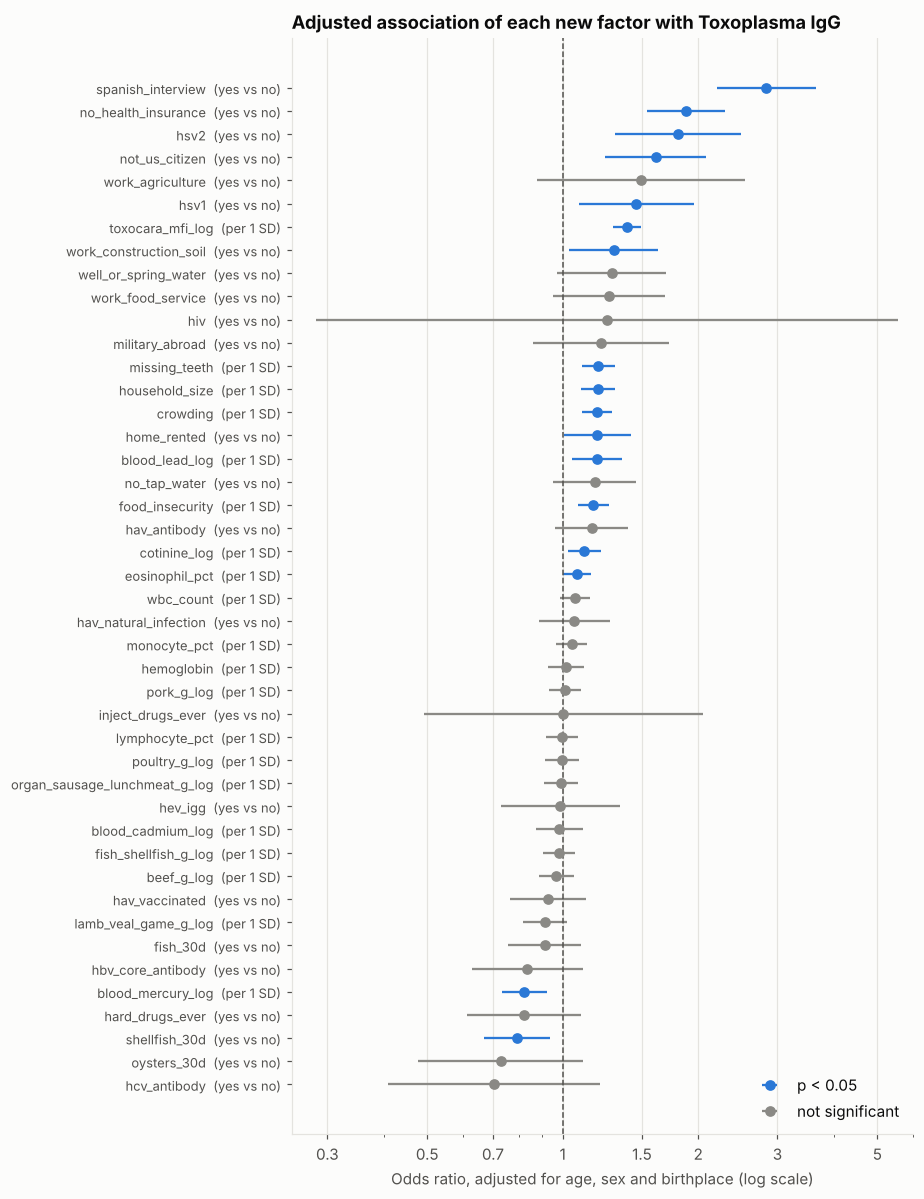

In [5]:
# Forest plot of the age/sex/birthplace-adjusted odds ratios
o = or_table.sort_values('adj OR').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8.5, 11))
ypos = np.arange(len(o))
sig_mask = o['adj p'] < 0.05
for mask, color, label in [(sig_mask, SINGLE, 'p < 0.05'), (~sig_mask, REFERENCE, 'not significant')]:
    ax.errorbar(o.loc[mask, 'adj OR'], ypos[mask],
                xerr=[o.loc[mask, 'adj OR'] - o.loc[mask, 'adj OR 95% low'],
                      o.loc[mask, 'adj OR 95% high'] - o.loc[mask, 'adj OR']],
                fmt='o', ms=6, color=color, ecolor=color, elinewidth=1.5, capsize=0, label=label)
ax.axvline(1, color=INK_2, lw=1, ls='--')
ax.set_xscale('log')
ticks = [0.3, 0.5, 0.7, 1, 1.5, 2, 3, 5]
ax.set_xticks(ticks)
ax.set_xticklabels([f'{t:g}' for t in ticks])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlim(0.25, 6)
ax.set_yticks(ypos)
ax.set_yticklabels([f"{f}  ({s})" for f, s in zip(o['feature'], o['scale'])], fontsize=8.5)
ax.set_xlabel('Odds ratio, adjusted for age, sex and birthplace (log scale)')
ax.set_title('Adjusted association of each new factor with Toxoplasma IgG')
ax.legend(loc='lower right')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

---
## 3. Models: old features vs new features
Same set-up as `scripts/train_baseline.py`, so the numbers are directly comparable with the earlier notebook:
the same stratified 80/20 split (`random_state=42`, the same 1,002 test rows), the same 15 cross-validation folds on the training set,
the same four models and hyper-parameters, and imputation/scaling fitted inside each fold.

| feature set | contents | count |
|---|---|---|
| `B_demo_toxocara` | the earlier best set: demographics + Toxocara | 7 |
| `C_all` | the earlier full set: B + sleep, health, smoking, alcohol, PHQ-9 | 13 |
| `D_C+questionnaire` | C + new food/water + living/work factors (no blood test needed) | 39 |
| `E_C+lab` | C + new lab factors (infections, blood, metals) | 31 |
| `F_everything` | C + all 44 new factors | 57 |

In [6]:
CATEGORICAL = ['RIAGENDR', 'RIDRETH3', 'yrs_in_us_grp', 'SLQ050', 'smoking_status', 'toxocara_pos']
NUMERIC = ['RIDAGEYR', 'DMDEDUC2', 'INDFMPIR', 'HSD010', 'SLD010H', 'drinks_per_day', 'phq9_total_score']
DEMOGRAPHICS = ['RIDAGEYR', 'RIAGENDR', 'RIDRETH3', 'yrs_in_us_grp', 'DMDEDUC2', 'INDFMPIR']
BEHAVIOUR = ['HSD010', 'SLD010H', 'SLQ050', 'smoking_status', 'drinks_per_day', 'phq9_total_score']
Q_NEW = bbf.Q_FOOD_WATER + bbf.Q_LIVING
LAB_NEW = bbf.LAB_INFECTION + bbf.LAB_BLOOD
C_ALL = DEMOGRAPHICS + ['toxocara_pos'] + BEHAVIOUR

FEATURE_SETS = {
    'B_demo_toxocara': DEMOGRAPHICS + ['toxocara_pos'],
    'C_all': C_ALL,
    'D_C+questionnaire': C_ALL + Q_NEW,
    'E_C+lab': C_ALL + LAB_NEW,
    'F_everything': C_ALL + Q_NEW + LAB_NEW,
}
for k, v in FEATURE_SETS.items():
    print(f'{k:18} {len(v):3d} features')


def make_preprocessor(features, categorical=CATEGORICAL):
    # categorical -> mode + one-hot; numeric (old and new) -> median + missing flag + scaling
    cat = [c for c in features if c in categorical]
    num = [c for c in features if c not in categorical]
    steps = [('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                               ('onehot', OneHotEncoder(drop='if_binary', handle_unknown='ignore',
                                                        sparse_output=False))]), cat)]
    if num:
        steps.append(('num', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)),
                                       ('scale', StandardScaler())]), num))
    return ColumnTransformer(steps)


MODELS = {   # identical to train_baseline.py
    'LogReg': LogisticRegression(C=1.0, max_iter=5000),
    'RandomForest': RandomForestClassifier(n_estimators=500, min_samples_leaf=10, n_jobs=1,
                                           random_state=RANDOM_STATE),
    'GradBoost': HistGradientBoostingClassifier(learning_rate=0.05, max_depth=3, max_iter=300,
                                                random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
                             colsample_bytree=0.8, eval_metric='logloss', n_jobs=1,
                             random_state=RANDOM_STATE),
}

X = df.drop(columns=[TARGET])
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y,
                                                    random_state=RANDOM_STATE)
CV_SPLITS = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
                 .split(X_train, y_train))
print(f'\nTrain {len(X_train):,} rows ({y_train.mean():.1%} positive), test {len(X_test):,} rows ({int(y_test.sum())} positive)')

# Check: same test rows as the earlier notebook (same SEQNs, because the 5,006 rows are in the same order)
base = pd.read_csv(bbf.BASE_CSV)
_, base_test = train_test_split(base, test_size=0.20, stratify=base[TARGET], random_state=RANDOM_STATE)
assert set(base_test['SEQN']) == set(X_test['SEQN']), 'test set differs from the earlier notebook'
print('Test set is identical to the one in toxo_model_overview.ipynb')

B_demo_toxocara      7 features
C_all               13 features
D_C+questionnaire   39 features
E_C+lab             31 features
F_everything        57 features

Train 4,004 rows (15.0% positive), test 1,002 rows (150 positive)
Test set is identical to the one in toxo_model_overview.ipynb


In [7]:
def run_fold(model_name, set_name, tr, va):
    cols = FEATURE_SETS[set_name]
    pipe = make_pipeline(make_preprocessor(cols), clone(MODELS[model_name]))
    pipe.fit(X_train.iloc[tr][cols], y_train.iloc[tr])
    p = pipe.predict_proba(X_train.iloc[va][cols])[:, 1]
    return model_name, set_name, va, p, roc_auc_score(y_train.iloc[va], p)

jobs = [(m, s, tr, va) for s in FEATURE_SETS for m in MODELS for tr, va in CV_SPLITS]
out = Parallel(n_jobs=-1)(delayed(run_fold)(*j) for j in jobs)

results, oof = {}, {}
for m, s, va, p, auc in out:
    results.setdefault((m, s), []).append(auc)
    acc = oof.setdefault((m, s), np.zeros(len(X_train)))
    acc[va] += p / 3          # every training row is validated once per repeat -> mean of 3
results = {k: np.array(v) for k, v in results.items()}

cv_table = pd.DataFrame([{'model': m, 'feature set': s, 'ROC-AUC mean': r.mean(), 'ROC-AUC sd': r.std()}
                         for (m, s), r in results.items()])
grid = cv_table.pivot(index='model', columns='feature set', values='ROC-AUC mean')[list(FEATURE_SETS)]
print('Mean cross-validated ROC-AUC (15 folds, training set). Rows = model, columns = feature set')
display(grid.round(4))
best_key = max(results, key=lambda k: results[k].mean())
print(f'Best: {best_key[0]} on {best_key[1]}, CV ROC-AUC {results[best_key].mean():.4f}')
print(f"Earlier best (LogReg, B_demo_toxocara): {results[('LogReg', 'B_demo_toxocara')].mean():.4f}")

Mean cross-validated ROC-AUC (15 folds, training set). Rows = model, columns = feature set


feature set,B_demo_toxocara,C_all,D_C+questionnaire,E_C+lab,F_everything
model,,,,,
GradBoost,0.7107,0.7040,0.6972,0.7050,0.7046
LogReg,0.7220,0.7183,0.7019,0.7157,0.6991
RandomForest,0.7159,0.7171,0.7178,0.7187,0.7233
XGBoost,0.7146,0.7132,0.7054,0.7094,0.7101


Best: RandomForest on F_everything, CV ROC-AUC 0.7233
Earlier best (LogReg, B_demo_toxocara): 0.7220


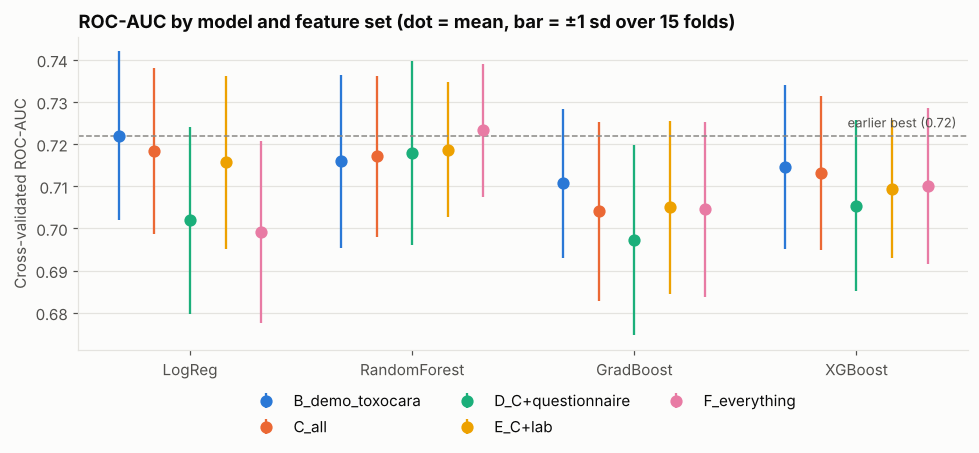

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.4))
models = list(MODELS)
width = 0.16
for i, s in enumerate(FEATURE_SETS):
    means = [results[(m, s)].mean() for m in models]
    sds = [results[(m, s)].std() for m in models]
    xs = np.arange(len(models)) + (i - 2) * width
    ax.errorbar(xs, means, yerr=sds, fmt='o', ms=7, color=SET_COLORS[s], elinewidth=1.5, capsize=0, label=s)
ax.axhline(results[('LogReg', 'B_demo_toxocara')].mean(), color=REFERENCE, ls='--', lw=1)
ax.text(len(models) - 0.55, results[('LogReg', 'B_demo_toxocara')].mean() + 0.002, 'earlier best (0.72)',
        color=INK_2, fontsize=8.5, ha='right')
ax.set_xticks(np.arange(len(models)))
ax.set_xticklabels(models)
ax.set_ylabel('Cross-validated ROC-AUC')
ax.set_title('ROC-AUC by model and feature set (dot = mean, bar = ±1 sd over 15 folds)')
ax.legend(ncol=3, loc='lower center', bbox_to_anchor=(0.5, -0.32))
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

### 3.1 Is any gain real? Paired test on the same folds
Same rule as `train_baseline.py`: a gain is **meaningful** only if the ROC-AUC rises by at least 0.01 **and** the corrected
repeated-CV t-test (Nadeau & Bengio) gives p < 0.05.

In [9]:
def compare(base, other):
    d = results[other] - results[base]
    k, ratio = len(d), 0.2 / 0.8
    t = d.mean() / np.sqrt((1 / k + ratio) * d.var(ddof=1)) if d.var(ddof=1) > 0 else 0.0
    p = 2 * stats.t.sf(abs(t), df=k - 1)
    return d.mean(), int((d > 0).sum()), p

rows = []
for m in MODELS:
    for s in ['D_C+questionnaire', 'E_C+lab', 'F_everything']:
        for b in ['C_all', 'B_demo_toxocara']:
            diff, wins, p = compare((m, b), (m, s))
            rows.append({'model': m, 'new set': s, 'vs': b, 'AUC change': diff,
                         'better in folds (of 15)': wins, 'p': p,
                         'verdict': 'MEANINGFUL' if (diff >= 0.01 and p < 0.05) else 'not meaningful'})
tests = pd.DataFrame(rows)
display(tests.round(4))
print(tests['verdict'].value_counts().to_string())

,model,new set,vs,AUC change,better in folds (of 15),p,verdict
0,LogReg,D_C+questionnaire,C_all,-0.0164,1,0.0144,not meaningful
1,LogReg,D_C+questionnaire,B_demo_toxocara,-0.0201,0,0.0110,not meaningful
2,LogReg,E_C+lab,C_all,-0.0026,7,0.7223,not meaningful
3,LogReg,E_C+lab,B_demo_toxocara,-0.0063,7,0.4202,not meaningful
4,LogReg,F_everything,C_all,-0.0192,1,0.0572,not meaningful
5,LogReg,F_everything,B_demo_toxocara,-0.0229,1,0.0354,not meaningful
6,RandomForest,D_C+questionnaire,C_all,0.0007,8,0.9084,not meaningful
7,RandomForest,D_C+questionnaire,B_demo_toxocara,0.0019,7,0.7701,not meaningful
8,RandomForest,E_C+lab,C_all,0.0016,6,0.7535,not meaningful
9,RandomForest,E_C+lab,B_demo_toxocara,0.0028,11,0.6181,not meaningful


verdict
not meaningful    24


### 3.2 Giving the new features a fair chance: regularised models and feature selection
The four models above keep the `train_baseline.py` settings. With 57 inputs, plain logistic regression (C = 1) can over-fit noise,
so this section also tries:

- **LogReg L1**: lasso logistic regression, strength chosen by inner 5-fold CV (drops useless columns by itself)
- **XGBoost slow**: shallower trees, smaller learning rate, column sub-sampling and stronger L2 penalty
- **`+selected`** sets: only the new factors that stay significant (p < 0.05) after adjusting for age, sex and birthplace,
  where the test is run on the **training rows only** (the test set is never used to pick features)

In [10]:
from sklearn.linear_model import LogisticRegressionCV

tr_adj = pd.DataFrame({'age_10y': X_train['RIDAGEYR'] / 10, 'male': (X_train['RIAGENDR'] == 1).astype(float),
                       'born_abroad': (X_train['DMDBORN4'] == 2).astype(float)})
selected = []
for col in bbf.NEW_FEATURES:
    x = X_train[col]
    xs = x if set(x.dropna().unique()) <= {0.0, 1.0} else (x - x.mean()) / x.std()
    m = x.notna()
    b, se = logit_fit(np.column_stack([xs[m].to_numpy(), tr_adj[m].to_numpy()]), y_train[m].to_numpy(float))
    if 2 * stats.norm.sf(abs(b[0] / se[0])) < 0.05:
        selected.append(col)
print(f'{len(selected)} new factors selected on the training rows:', ', '.join(selected))

FEATURE_SETS['B+selected'] = FEATURE_SETS['B_demo_toxocara'] + selected
FEATURE_SETS['C+selected'] = C_ALL + selected
SET_COLORS.update({'B+selected': '#008300', 'C+selected': '#8a8985'})
EXTRA_MODELS = {
    'LogReg L1': LogisticRegressionCV(Cs=np.logspace(-3, 1, 9), cv=5, penalty='l1', solver='liblinear',
                                      scoring='roc_auc', max_iter=5000),
    'XGBoost slow': XGBClassifier(n_estimators=600, learning_rate=0.02, max_depth=2, subsample=0.8,
                                  colsample_bytree=0.5, min_child_weight=10, reg_lambda=5,
                                  eval_metric='logloss', n_jobs=1, random_state=RANDOM_STATE),
}
MODELS.update(EXTRA_MODELS)

new_jobs = [(m, s, tr, va) for s in FEATURE_SETS for m in MODELS
            if (m, s) not in results for tr, va in CV_SPLITS]
out = Parallel(n_jobs=-1)(delayed(run_fold)(*j) for j in new_jobs)
for m, s, va, p, auc in out:
    results.setdefault((m, s), [])
    results[(m, s)] = np.append(results[(m, s)], auc)
    acc = oof.setdefault((m, s), np.zeros(len(X_train)))
    acc[va] += p / 3

show_sets = ['B_demo_toxocara', 'C_all', 'F_everything', 'B+selected', 'C+selected']
grid2 = pd.DataFrame({s: {m: results[(m, s)].mean() for m in MODELS} for s in show_sets})
print('\nMean cross-validated ROC-AUC (15 folds), all models x selected feature sets')
display(grid2.round(4))
rows = []
for m in MODELS:
    for s in ['F_everything', 'B+selected', 'C+selected']:
        diff, wins, p = compare(('LogReg', 'B_demo_toxocara'), (m, s))
        rows.append({'model': m, 'feature set': s, 'AUC change vs earlier best': diff,
                     'better in folds (of 15)': wins, 'p': p,
                     'verdict': 'MEANINGFUL' if (diff >= 0.01 and p < 0.05) else 'not meaningful'})
tests2 = pd.DataFrame(rows)
display(tests2.round(4))

15 new factors selected on the training rows: hsv1, hsv2, toxocara_mfi_log, eosinophil_pct, blood_lead_log, blood_mercury_log, shellfish_30d, household_size, crowding, spanish_interview, not_us_citizen, work_construction_soil, food_insecurity, no_health_insurance, missing_teeth



Mean cross-validated ROC-AUC (15 folds), all models x selected feature sets


,B_demo_toxocara,C_all,F_everything,B+selected,C+selected
LogReg,0.7220,0.7183,0.6991,0.7208,0.7175
RandomForest,0.7159,0.7171,0.7233,0.7210,0.7225
GradBoost,0.7107,0.7040,0.7046,0.7032,0.7029
XGBoost,0.7146,0.7132,0.7101,0.7116,0.7097
LogReg L1,0.7233,0.7221,0.7211,0.7243,0.7248
XGBoost slow,0.7229,0.7205,0.7209,0.7245,0.7233


,model,feature set,AUC change vs earlier best,better in folds (of 15),p,verdict
0,LogReg,F_everything,-0.0229,1,0.0354,not meaningful
1,LogReg,B+selected,-0.0012,8,0.8772,not meaningful
2,LogReg,C+selected,-0.0045,5,0.5865,not meaningful
3,RandomForest,F_everything,0.0013,9,0.8377,not meaningful
4,RandomForest,B+selected,-0.0010,8,0.9032,not meaningful
5,RandomForest,C+selected,0.0005,9,0.9477,not meaningful
6,GradBoost,F_everything,-0.0174,3,0.1113,not meaningful
7,GradBoost,B+selected,-0.0187,2,0.1081,not meaningful
8,GradBoost,C+selected,-0.0191,4,0.1359,not meaningful
9,XGBoost,F_everything,-0.0119,3,0.1771,not meaningful


---
## 4. Held-out test set (1,002 people, 150 positive)
Each model is fitted once on the whole training set and scored once on the test set.

**Threshold.** At the default 0.5 cut-off the models call almost everyone negative (that is why accuracy ≈ 85%).
For a screening tool a lower cut-off is needed. The cut-off below is chosen **on the training set only**
(out-of-fold predictions from the 15 CV folds, maximising balanced accuracy = Youden's J), then applied unchanged to the test set.

In [11]:
def fit_predict(model_name, set_name):
    cols = FEATURE_SETS[set_name]
    pipe = make_pipeline(make_preprocessor(cols), clone(MODELS[model_name])).fit(X_train[cols], y_train)
    return (model_name, set_name), pipe, pipe.predict_proba(X_test[cols])[:, 1]

fitted = Parallel(n_jobs=-1)(delayed(fit_predict)(m, s) for s in FEATURE_SETS for m in MODELS)
pipes = {k: p for k, p, _ in fitted}
test_proba = {k: pr for k, _, pr in fitted}


def best_threshold(y_true, p):
    fpr, tpr, thr = roc_curve(y_true, p)
    return thr[np.argmax(tpr - fpr)]


def scores(y_true, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {'accuracy': accuracy_score(y_true, pred), 'balanced accuracy': balanced_accuracy_score(y_true, pred),
            'sensitivity': tp / (tp + fn), 'specificity': tn / (tn + fp),
            'F1 (weighted)': f1_score(y_true, pred, average='weighted'), 'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn}

rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
boot_idx = []
while len(boot_idx) < 1000:
    idx = rng.integers(0, len(y_arr), len(y_arr))
    if 0 < y_arr[idx].sum() < len(idx):
        boot_idx.append(idx)

rows = []
for (m, s), p in test_proba.items():
    thr = best_threshold(y_train, oof[(m, s)])
    boots = np.array([roc_auc_score(y_arr[i], p[i]) for i in boot_idx])
    at05 = scores(y_arr, p, 0.5)
    tuned = scores(y_arr, p, thr)
    rows.append({'model': m, 'feature set': s, 'CV AUC': results[(m, s)].mean(),
                 'test AUC': roc_auc_score(y_arr, p),
                 'test AUC 95% CI': f'{np.percentile(boots, 2.5):.3f}-{np.percentile(boots, 97.5):.3f}',
                 'accuracy @0.5': at05['accuracy'], 'threshold': thr,
                 'accuracy @thr': tuned['accuracy'], 'balanced acc @thr': tuned['balanced accuracy'],
                 'sensitivity @thr': tuned['sensitivity'], 'specificity @thr': tuned['specificity'],
                 'F1 weighted @thr': tuned['F1 (weighted)']})
test_table = pd.DataFrame(rows)
display(test_table.round(3))

,model,feature set,CV AUC,test AUC,test AUC 95% CI,accuracy @0.5,threshold,accuracy @thr,balanced acc @thr,sensitivity @thr,specificity @thr,F1 weighted @thr
0,LogReg,B_demo_toxocara,0.722,0.712,0.670-0.759,0.853,0.128,0.623,0.660,0.713,0.607,0.677
1,RandomForest,B_demo_toxocara,0.716,0.711,0.667-0.760,0.853,0.130,0.578,0.656,0.767,0.545,0.637
2,GradBoost,B_demo_toxocara,0.711,0.699,0.656-0.748,0.845,0.150,0.650,0.651,0.653,0.649,0.699
3,XGBoost,B_demo_toxocara,0.715,0.704,0.660-0.753,0.849,0.138,0.628,0.644,0.667,0.621,0.681
4,LogReg L1,B_demo_toxocara,0.723,0.710,0.668-0.757,0.854,0.144,0.663,0.667,0.673,0.661,0.710
5,XGBoost slow,B_demo_toxocara,0.723,0.712,0.665-0.759,0.853,0.145,0.646,0.649,0.653,0.644,0.696
6,LogReg,C_all,0.718,0.713,0.669-0.760,0.856,0.145,0.670,0.657,0.640,0.675,0.715
7,RandomForest,C_all,0.717,0.697,0.650-0.745,0.849,0.152,0.629,0.661,0.707,0.615,0.682
8,GradBoost,C_all,0.704,0.700,0.655-0.749,0.853,0.135,0.627,0.654,0.693,0.615,0.680
9,XGBoost,C_all,0.713,0.694,0.649-0.743,0.852,0.152,0.671,0.650,0.620,0.680,0.716


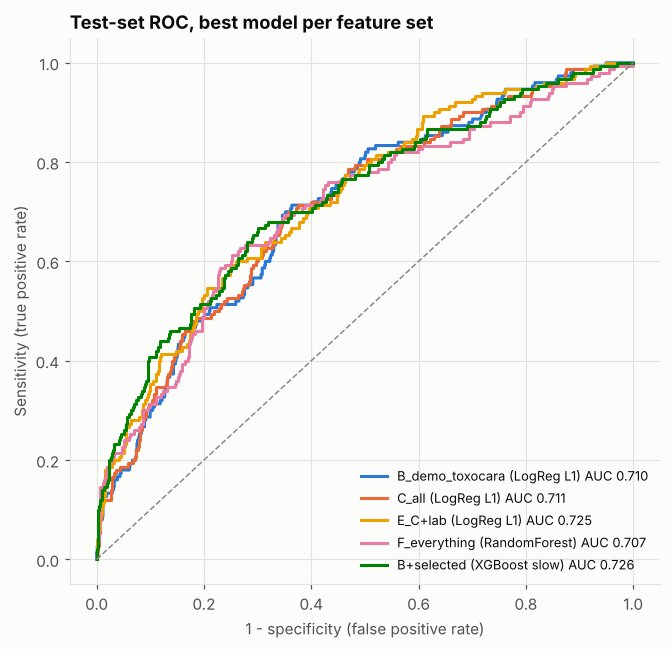

In [12]:
# ROC curves on the test set: best model (by CV AUC) within each feature set
fig, ax = plt.subplots(figsize=(6.2, 6))
for s in ['B_demo_toxocara', 'C_all', 'E_C+lab', 'F_everything', 'B+selected']:
    m = max(MODELS, key=lambda mm: results[(mm, s)].mean())
    fpr, tpr, _ = roc_curve(y_test, test_proba[(m, s)])
    ax.plot(fpr, tpr, lw=2, color=SET_COLORS[s],
            label=f'{s} ({m}) AUC {roc_auc_score(y_test, test_proba[(m, s)]):.3f}')
ax.plot([0, 1], [0, 1], color=REFERENCE, ls='--', lw=1)
ax.set_xlabel('1 - specificity (false positive rate)')
ax.set_ylabel('Sensitivity (true positive rate)')
ax.set_title('Test-set ROC, best model per feature set')
ax.legend(loc='lower right', fontsize=8.5)
plt.tight_layout()
plt.show()

---
## 5. Which features does the model actually use?
Permutation importance on the **test set** for XGBoost with all features (`F_everything`): how much test ROC-AUC drops when one
input column is shuffled (20 repeats). Bars near zero mean the model gains nothing from that column.

,feature,AUC drop mean,AUC drop sd,new?
0,RIDAGEYR,0.0482,0.0094,earlier
1,toxocara_mfi_log,0.0334,0.0067,new
2,RIDRETH3,0.0149,0.0033,earlier
3,yrs_in_us_grp,0.0060,0.0040,earlier
4,monocyte_pct,0.0046,0.0027,new
5,hemoglobin,0.0043,0.0018,new
6,missing_teeth,0.0040,0.0043,new
7,blood_mercury_log,0.0037,0.0015,new
8,INDFMPIR,0.0034,0.0028,earlier
9,spanish_interview,0.0034,0.0049,new


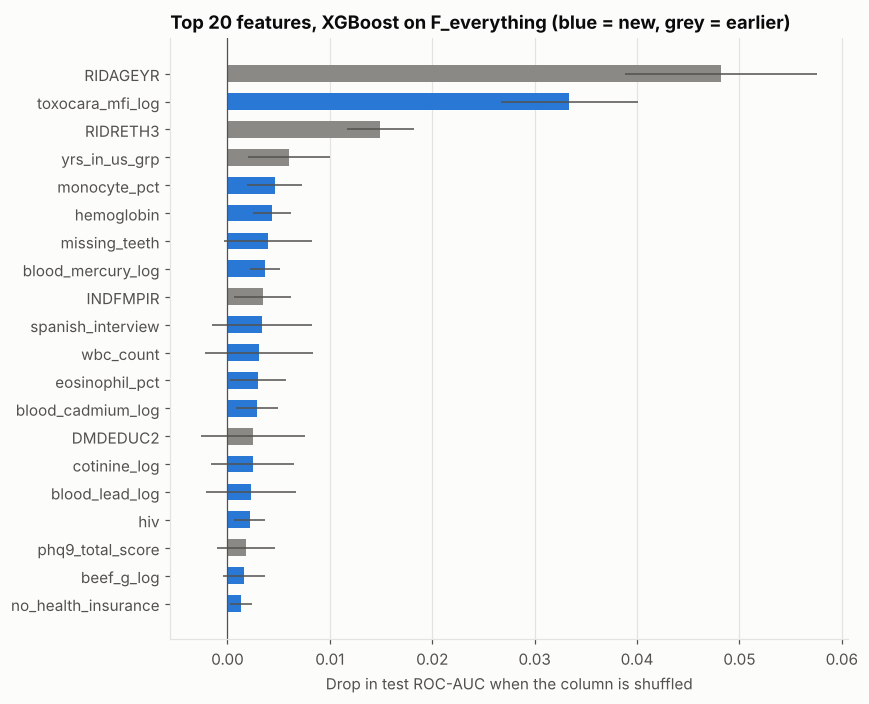

In [13]:
imp_key = ('XGBoost', 'F_everything')
cols = FEATURE_SETS[imp_key[1]]
pi = permutation_importance(pipes[imp_key], X_test[cols], y_test, scoring='roc_auc', n_repeats=20,
                            random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({'feature': cols, 'AUC drop mean': pi.importances_mean, 'AUC drop sd': pi.importances_std})
imp['new?'] = np.where(imp['feature'].isin(bbf.NEW_FEATURES), 'new', 'earlier')
imp = imp.sort_values('AUC drop mean', ascending=False).reset_index(drop=True)
display(imp.head(25).round(4))

top = imp.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6.5))
colors = [SINGLE if n == 'new' else REFERENCE for n in top['new?']]
ax.barh(top['feature'], top['AUC drop mean'], xerr=top['AUC drop sd'], color=colors, height=0.6,
        error_kw={'elinewidth': 1, 'ecolor': INK_2})
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_xlabel('Drop in test ROC-AUC when the column is shuffled')
ax.set_title('Top 20 features, XGBoost on F_everything (blue = new, grey = earlier)')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

---
## 6. More rows instead of more columns: pooling NHANES 2009-2014
The Toxoplasma test was run in **three** NHANES cycles with the **same** Bio-Rad IgG EIA and the **same** cut-off (≥ 33 IU/mL):
2009-2010 (`SSTOXO_F`), 2011-2012 (`SSTOXO_G`) and 2013-2014 (`SSTOXO_H`). `build_bio_features.py` rebuilds the exact
`cleaning2.py` cohort for each cycle (the rebuilt 2013-2014 rows match `nhanes_adult_toxo_clean.csv` value for value) and adds the same 44 factors.

Differences: 2009-2010 has no Toxocara test and no "served abroad" question (left missing, then imputed), and race uses `RIDRETH1`
(5 groups) because the separate Asian group only starts in 2011.

**Fair test:** the extra 2009-2012 rows are added to the **training** set only. Every model is still scored on the **same 1,002
2013-2014 test rows** as above.

In [14]:
print(pooled.groupby('cycle')[TARGET].agg(n='size', positive='sum', rate='mean').round(3))

P_CATEGORICAL = ['RIAGENDR', 'RIDRETH1', 'yrs_in_us_grp', 'SLQ050', 'smoking_status', 'toxocara_pos']
P_C_ALL = [c if c != 'RIDRETH3' else 'RIDRETH1' for c in C_ALL]
P_SETS = {'C_all': P_C_ALL, 'F_everything': P_C_ALL + Q_NEW + LAB_NEW}

test_seqn = set(X_test['SEQN'])
pool_test = pooled[pooled['SEQN'].isin(test_seqn)].set_index('SEQN').loc[X_test['SEQN']].reset_index()
assert len(pool_test) == len(X_test) and (pool_test[TARGET].to_numpy() == y_arr).all()
h_train = pooled[(pooled['cycle'] == '2013-2014') & ~pooled['SEQN'].isin(test_seqn)]
pool_train = pooled[~pooled['SEQN'].isin(test_seqn)]
print(f'\nTraining rows: 2013-2014 only = {len(h_train):,};  2009-2014 pooled = {len(pool_train):,}')


def fit_eval(train, set_name, model_name, seed=RANDOM_STATE):
    cols = P_SETS[set_name]
    model = clone(MODELS[model_name])
    if 'random_state' in model.get_params():
        model.set_params(random_state=seed)
    pipe = make_pipeline(make_preprocessor(cols, P_CATEGORICAL), model).fit(train[cols], train[TARGET])
    return roc_auc_score(pool_test[TARGET], pipe.predict_proba(pool_test[cols])[:, 1])

jobs = [(tr_name, tr, s, m) for tr_name, tr in [('2013-2014 only', h_train), ('2009-2014 pooled', pool_train)]
        for s in P_SETS for m in MODELS]
aucs = Parallel(n_jobs=-1)(delayed(fit_eval)(tr, s, m) for _, tr, s, m in jobs)
pool_res = pd.DataFrame([{'training data': j[0], 'feature set': j[2], 'model': j[3], 'test AUC (2013-14)': a}
                         for j, a in zip(jobs, aucs)])
display(pool_res.pivot_table(index=['feature set', 'model'], columns='training data',
                             values='test AUC (2013-14)').round(4))

              n  positive   rate
cycle                           
2009-2010  5057       975  0.193
2011-2012  4586       770  0.168
2013-2014  5006       750  0.150

Training rows: 2013-2014 only = 4,004;  2009-2014 pooled = 13,647


training data              2009-2014 pooled  2013-2014 only
feature set  model                                         
C_all        GradBoost               0.7115          0.6921
             LogReg                  0.7143          0.7123
             LogReg L1               0.7140          0.7105
             RandomForest            0.6988          0.6960
             XGBoost                 0.7124          0.6969
             XGBoost slow            0.7120          0.7071
F_everything GradBoost               0.7110          0.7167
             LogReg                  0.7311          0.7276
             LogReg L1               0.7238          0.7062
             RandomForest            0.7002          0.7112
             XGBoost                 0.7167          0.7282
             XGBoost slow            0.7131          0.7257

### 6.1 Learning curve: would even more rows help?
Random subsets of the pooled training rows (5 draws per size), scored on the same 2013-2014 test set.
If the curve is flat at the right-hand end, collecting more rows of the *same* variables will not raise the score.

model,LogReg,XGBoost
n,,
1000,0.6734,0.6624
2000,0.7017,0.6832
4000,0.7168,0.6992
7000,0.7269,0.7126
10000,0.7311,0.7183
13647,0.7311,0.7160


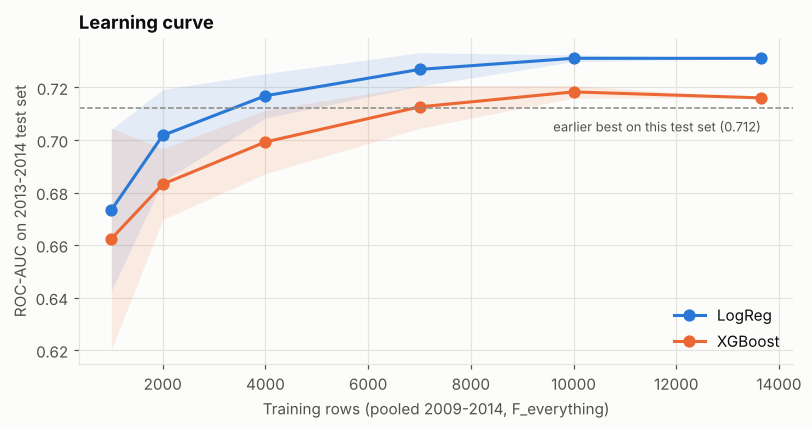

In [15]:
sizes = [1000, 2000, 4000, 7000, 10000, len(pool_train)]
lc_jobs = []
for n in sizes:
    for rep in range(5 if n < len(pool_train) else 1):
        sub = pool_train.sample(n=n, random_state=rep) if n < len(pool_train) else pool_train
        for m in ['LogReg', 'XGBoost']:
            lc_jobs.append((n, rep, m, sub))
lc_auc = Parallel(n_jobs=-1)(delayed(fit_eval)(sub, 'F_everything', m, rep) for n, rep, m, sub in lc_jobs)
lc = pd.DataFrame([{'n': j[0], 'model': j[2], 'auc': a} for j, a in zip(lc_jobs, lc_auc)])
lc_sum = lc.groupby(['model', 'n'])['auc'].agg(['mean', 'std']).reset_index()
display(lc_sum.pivot(index='n', columns='model', values='mean').round(4))

fig, ax = plt.subplots(figsize=(7.5, 4))
for m, color in [('LogReg', SINGLE), ('XGBoost', '#eb6834')]:
    d = lc_sum[lc_sum['model'] == m]
    ax.plot(d['n'], d['mean'], marker='o', ms=7, lw=2, color=color, label=m)
    ax.fill_between(d['n'], d['mean'] - d['std'].fillna(0), d['mean'] + d['std'].fillna(0), color=color, alpha=0.12, lw=0)
ax.axhline(roc_auc_score(y_test, test_proba[('LogReg', 'B_demo_toxocara')]), color=REFERENCE, ls='--', lw=1)
ax.text(sizes[-1], roc_auc_score(y_test, test_proba[('LogReg', 'B_demo_toxocara')]) - 0.009,
        'earlier best on this test set (0.712)', color=INK_2, fontsize=8.5, ha='right')
ax.set_xlabel('Training rows (pooled 2009-2014, F_everything)')
ax.set_ylabel('ROC-AUC on 2013-2014 test set')
ax.set_title('Learning curve')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

---
## 7. Summary

In [16]:
line = '=' * 74
old = ('LogReg', 'B_demo_toxocara')
best_cv = max(results, key=lambda k: results[k].mean())
tt = test_table.set_index(['model', 'feature set'])
print(line)
print('  RESULT: does adding NHANES biological / exposure factors raise ROC-AUC?')
print(line)
print(f'  New factors added            : {len(bbf.NEW_FEATURES)} (from 20 NHANES 2013-2014 files)')
print(f'  Earlier best  {old[0]:>8} / {old[1]:<18}: CV AUC {results[old].mean():.3f}   test AUC {tt.loc[old, "test AUC"]:.3f}')
print(f'  New best      {best_cv[0]:>8} / {best_cv[1]:<18}: CV AUC {results[best_cv].mean():.3f}   test AUC {tt.loc[best_cv, "test AUC"]:.3f}')
for s in ['D_C+questionnaire', 'E_C+lab', 'F_everything', 'B+selected', 'C+selected']:
    b = max(MODELS, key=lambda m: results[(m, s)].mean())
    print(f'  {s:<19} best = {b:<12}: CV AUC {results[(b, s)].mean():.3f}   test AUC {tt.loc[(b, s), "test AUC"]:.3f}')
n_meaningful = int((tests['verdict'] == 'MEANINGFUL').sum()) + int((tests2['verdict'] == 'MEANINGFUL').sum())
print(f'  Meaningful gains (>= +0.01 AUC and p < 0.05): {n_meaningful} of {len(tests) + len(tests2)} comparisons')
best_test = test_table.sort_values('test AUC').iloc[-1]
print(f'  Highest single test AUC     : {best_test["test AUC"]:.3f} ({best_test["model"]} / {best_test["feature set"]}, '
      f'95% CI {best_test["test AUC 95% CI"]}) - chosen after looking at the test set, so optimistic')
pr = pool_res.pivot_table(index=['feature set', 'model'], columns='training data', values='test AUC (2013-14)')
print(f'  Pooling 2009-2014 (3x rows), best test AUC  : {pr["2009-2014 pooled"].max():.3f} '
      f'(vs {pr["2013-2014 only"].max():.3f} with 2013-2014 rows only)')
print(line)
r = tt.loc[best_cv]
print(f'  Best model at its training-chosen threshold ({r["threshold"]:.3f}) on the test set:')
print(f'    accuracy {r["accuracy @thr"]:.1%} | balanced accuracy {r["balanced acc @thr"]:.1%} | '
      f'sensitivity {r["sensitivity @thr"]:.1%} | specificity {r["specificity @thr"]:.1%} | weighted F1 {r["F1 weighted @thr"]:.3f}')
print(f'  (At the 0.5 threshold: accuracy {r["accuracy @0.5"]:.1%}; always-negative = {1 - y_test.mean():.1%})')
print(line)

  RESULT: does adding NHANES biological / exposure factors raise ROC-AUC?
  New factors added            : 44 (from 20 NHANES 2013-2014 files)
  Earlier best    LogReg / B_demo_toxocara   : CV AUC 0.722   test AUC 0.712
  New best      LogReg L1 / C+selected        : CV AUC 0.725   test AUC 0.725
  D_C+questionnaire   best = XGBoost slow: CV AUC 0.719   test AUC 0.705
  E_C+lab             best = LogReg L1   : CV AUC 0.721   test AUC 0.725
  F_everything        best = RandomForest: CV AUC 0.723   test AUC 0.707
  B+selected          best = XGBoost slow: CV AUC 0.724   test AUC 0.726
  C+selected          best = LogReg L1   : CV AUC 0.725   test AUC 0.725
  Meaningful gains (>= +0.01 AUC and p < 0.05): 0 of 42 comparisons
  Highest single test AUC     : 0.733 (XGBoost / E_C+lab, 95% CI 0.688-0.780) - chosen after looking at the test set, so optimistic
  Pooling 2009-2014 (3x rows), best test AUC  : 0.731 (vs 0.728 with 2013-2014 rows only)
  Best model at its training-chosen threshold (

### What the numbers say

**1. The new factors do not raise the score.** 44 factors, 6 models and 7 feature sets give 42 paired comparisons against the earlier best;
none is a meaningful gain (≥ +0.01 ROC-AUC with p < 0.05). The best cross-validated ROC-AUC moves from 0.722 to 0.725. Test-set AUCs of
0.72-0.73 look a little higher than 0.712, but the 95% interval is about ±0.045 wide, so this is within noise.

**2. Why.** Toxoplasma IgG stays positive for life, so it records exposure over decades (often in childhood or in the country of birth).
NHANES 2013-2014 has no question on the direct routes (cats, undercooked meat, gardening or soil, unwashed produce). What it does have
(yesterday's meals, current job, current blood values) describes the present, not the moment of infection. Most of the factors that are
linked to Toxoplasma (Spanish-language interview, citizenship, crowding, no insurance, missing teeth, HSV-1) carry the same
migration and poverty signal that age, birthplace, ethnicity and education already give the model.

**3. More rows do not fix it either.** Tripling the cohort with 2009-2012 (same assay) moves the best test AUC from 0.728 to 0.731,
and the learning curve is flat beyond about 7,000-10,000 rows. The limit is what NHANES measures, not how many people it measured.

**4. What is still worth reporting.** 17 of the 44 factors stay significant after adjusting for age, sex and birthplace (section 2.2):
Toxocara antibody level, HSV-1, HSV-2, blood lead, eosinophils, missing teeth, crowding, household size, food insecurity, renting,
construction/grounds work (soil contact), no health insurance, citizenship, Spanish interview and cotinine go **up** with Toxoplasma;
shellfish and blood mercury (markers of a fish-eating, higher-income diet) go **down**. These are real epidemiological findings, even
though they do not improve prediction.

**5. For the paper.** Report ROC-AUC (≈ 0.72) rather than accuracy, and if a single "accuracy" is needed, report balanced accuracy,
sensitivity and specificity at a threshold chosen on the training data (about 65% balanced accuracy, 70% sensitivity). A plain accuracy
of 85-86% is no better than calling everyone negative.